In [1]:
!pip install gradio sweetviz -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 91.2 MB/s eta 0:00:00


Loading 'student dropout.csv'...

--- DATASET OVERVIEW ---
Dataset Shape: 649 students, 34 variables.
Missing Values per Column:
 Series([], dtype: int64)


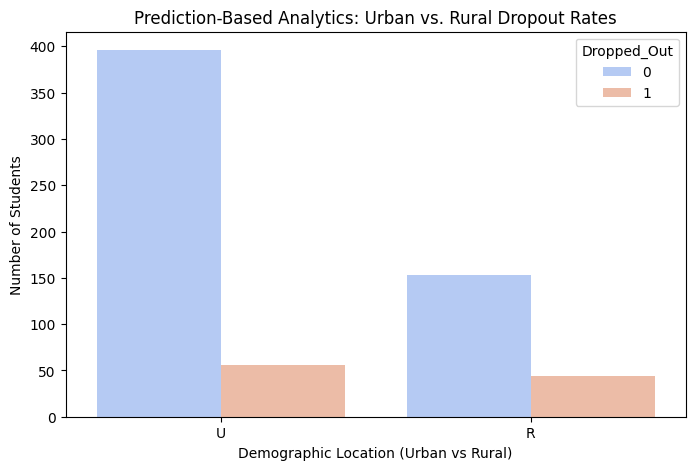

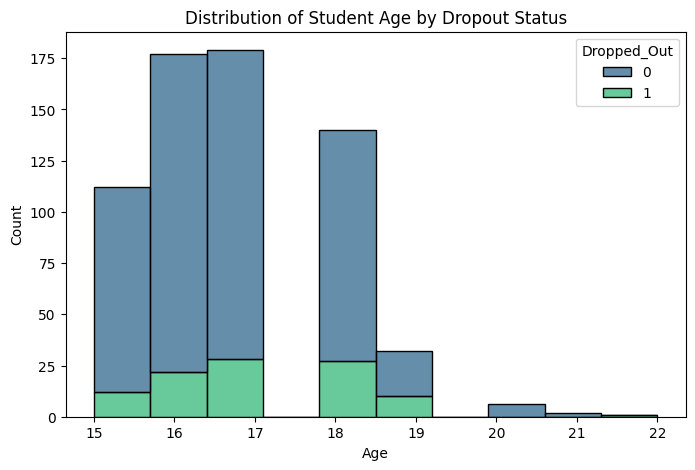

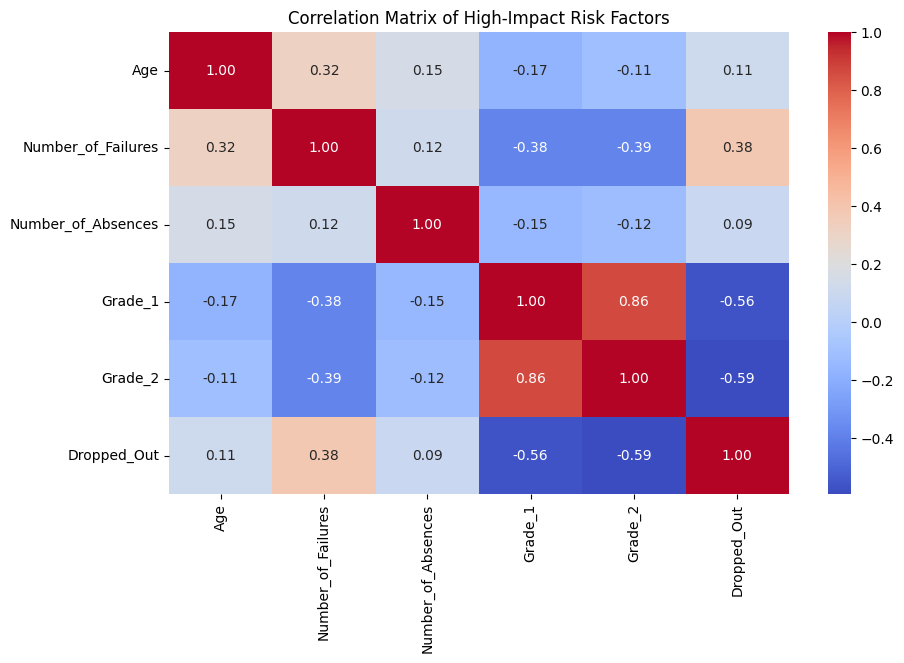


✅ Manual Exploratory Data Analysis complete. All plots saved successfully!

Running Evolutionary Genetic Feature Selection Optimization...
Optimization Complete! Selected 12 features.

🧠 Testing Various Transfer Functions on Multi-Layer Perceptron (MLP)...

======= TRANSFER FUNCTION EVALUATION =======
                F1-Score  Recall
ANN (logistic)    0.7556    0.85
ANN (tanh)        0.6829    0.70
ANN (relu)        0.7000    0.70

🔄 Generating complete performance evaluation matrix on test dataset...

======= FULL EVALUATION REPORT PERFORMANCE MATRIX =======
                        Baseline F1  Hybrid F1  Baseline Recall  Hybrid Recall  Baseline ROC-AUC  Hybrid ROC-AUC
Logistic Regression          0.7200     0.7170             0.90           0.95            0.9368          0.9500
Random Forest                0.7083     0.6809             0.85           0.80            0.9441          0.9255
Support Vector Machine       0.6957     0.7059             0.80           0.90            0.93

In [2]:
import numpy as np
import pandas as pd
import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, recall_score, roc_auc_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.base import clone

# =====================================================================
# 1. LOAD DATASET & EXECUTE MANUAL EXPLORATORY DATA ANALYSIS (EDA)
# =====================================================================
print("Loading 'student dropout.csv'...")
df = pd.read_csv('student dropout.csv')

# Clean target variable to be binary (1 = Dropped Out, 0 = Retained)
df['Dropped_Out'] = df['Dropped_Out'].astype(str).str.lower().map({'true': 1, 'false': 0, '1': 1, '0': 0})

print("\n--- DATASET OVERVIEW ---")
print(f"Dataset Shape: {df.shape[0]} students, {df.shape[1]} variables.")
print("Missing Values per Column:\n", df.isnull().sum()[df.isnull().sum() > 0])

# --- PLOT 1: URBAN VS RURAL ANALYTICS
demographic_col = 'Address'

if demographic_col in df.columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=demographic_col, hue='Dropped_Out', palette='coolwarm')
    plt.title("Prediction-Based Analytics: Urban vs. Rural Dropout Rates")
    plt.xlabel("Demographic Location (Urban vs Rural)")
    plt.ylabel("Number of Students")
    plt.savefig('urban_vs_rural_dropouts.png', bbox_inches='tight')
    plt.show()
else:
    print(f"⚠️ Could not find column '{demographic_col}'. Please update the variable name on line 26.")

# --- PLOT 2: AGE DISTRIBUTION ---
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Dropped_Out', multiple="stack", bins=10, palette='viridis')
plt.title("Distribution of Student Age by Dropout Status")
plt.xlabel("Age")
plt.savefig('age_distribution.png', bbox_inches='tight')
plt.show()

# --- PLOT 3: FEATURE CORRELATION HEATMAP ---
plt.figure(figsize=(10, 6))
top_corr_features = ['Age', 'Number_of_Failures', 'Number_of_Absences', 'Grade_1', 'Grade_2', 'Dropped_Out']
sns.heatmap(df[top_corr_features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of High-Impact Risk Factors")
plt.savefig('student_dropout_correlation.png', bbox_inches='tight')
plt.show()

print("\n✅ Manual Exploratory Data Analysis complete. All plots saved successfully!")

# =====================================================================
# 2. DATA PREPROCESSING PIPELINE (FIXED FOR TARGET LEAKAGE)
# =====================================================================
# Dynamically find and remove any alternative target columns that cause leakage
leakage_columns = ['Dropped_Out', 'Dropout', 'status', 'Status', 'Final_Grade']
columns_to_drop = [col for col in leakage_columns if col in df.columns]

X = df.drop(columns=columns_to_drop)
y = df['Dropped_Out']

categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Handle any unexpected missing rows safely via median imputation
num_imputer = SimpleImputer(strategy='median')
X[numeric_cols] = num_imputer.fit_transform(X[numeric_cols])

# Convert categorical labels to distinct structural integers
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

# Stratified Split to preserve class imbalance ratios across subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

# =====================================================================
# 3. UNSTUDIED HYBRID ELEMENT: GENETIC ALGORITHM FEATURE SELECTION
# =====================================================================
def genetic_algorithm_feature_selection(X_train, y_train, generations=5, population_size=8):
    np.random.seed(42)

    n_features = X_train.shape[1]
    population = np.random.randint(2, size=(population_size, n_features))

    for i in range(population_size):
        if np.sum(population[i]) == 0: population[i][np.random.randint(0, n_features)] = 1

    best_chromosome = None
    best_fitness = -1

    print("\nRunning Evolutionary Genetic Feature Selection Optimization...")
    for gen in range(generations):
        fitness_scores = []
        for chromosome in population:
            selected = [X_train.columns[i] for i, val in enumerate(chromosome) if val == 1]
            if len(selected) == 0:
                fitness_scores.append(0)
                continue

            evaluator = RandomForestClassifier(n_estimators=30, max_depth=5, random_state=42, class_weight='balanced')
            evaluator.fit(X_train[selected], y_train)
            f1 = f1_score(y_train, evaluator.predict(X_train[selected]))

            # Merit framework: Penalize redundant features
            penalty = 0.05 * (len(selected) / n_features)
            fitness_scores.append(f1 - penalty)

        max_idx = np.argmax(fitness_scores)
        if fitness_scores[max_idx] > best_fitness:
            best_fitness = fitness_scores[max_idx]
            best_chromosome = population[max_idx].copy()

        sorted_indices = np.argsort(fitness_scores)[::-1]
        parents = population[sorted_indices[:population_size // 2]]
        new_pop = list(parents)
        while len(new_pop) < population_size:
            p1, p2 = parents[np.random.randint(0, len(parents))], parents[np.random.randint(0, len(parents))]
            child = np.concatenate([p1[:n_features//2], p2[n_features//2:]])
            if np.random.rand() < 0.1: child[np.random.randint(0, n_features)] = 1 - child[np.random.randint(0, n_features)]
            if np.sum(child) > 0: new_pop.append(child)
        population = np.array(new_pop)[:population_size]

    return [X_train.columns[i] for i, val in enumerate(best_chromosome) if val == 1]

selected_features = genetic_algorithm_feature_selection(X_train_scaled, y_train)
print(f"Optimization Complete! Selected {len(selected_features)} features.")

# =====================================================================
# 3.5 TRANSFER FUNCTION TESTING (NEURAL NETWORK)
# =====================================================================
from sklearn.neural_network import MLPClassifier

print("\n🧠 Testing Various Transfer Functions on Multi-Layer Perceptron (MLP)...")

# The three classic transfer functions required for ML testing
transfer_functions = ['logistic', 'tanh', 'relu']
tf_results = {}

for tf in transfer_functions:
    # Build a standard neural network swapping out the transfer function
    mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation=tf, max_iter=1000, random_state=42)

    # Train and Predict on the scaled baseline data
    mlp.fit(X_train_scaled, y_train)
    preds = mlp.predict(X_test_scaled)

    # Store metrics
    tf_results[f"ANN ({tf})"] = {
        'F1-Score': round(f1_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4)
    }

# Display the mini-matrix for the presentation slide
tf_df = pd.DataFrame(tf_results).T
print("\n======= TRANSFER FUNCTION EVALUATION =======")
print(tf_df.to_string())
print("============================================")

# =====================================================================
# 4. COMPARATIVE PERFORMANCE MATRIX EVALUATION
# =====================================================================
base_models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', solver='liblinear', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, class_weight='balanced', random_state=42),
    "Support Vector Machine": SVC(probability=True, kernel='rbf', class_weight='balanced', random_state=42)
}

results = {}

print("\n🔄 Generating complete performance evaluation matrix on test dataset...")
for name, model_template in base_models.items():
    # Clone template models to keep their states isolated
    baseline_model = clone(model_template)
    hybrid_model = clone(model_template)

    # 1. Evaluate Baseline Model (Using all 33 raw features)
    baseline_model.fit(X_train_scaled, y_train)
    base_preds = baseline_model.predict(X_test_scaled)
    base_probs = baseline_model.predict_proba(X_test_scaled)[:, 1]

    # 2. Evaluate Hybrid Model (Using ONLY features selected by the Genetic Algorithm)
    hybrid_model.fit(X_train_scaled[selected_features], y_train)
    hy_preds = hybrid_model.predict(X_test_scaled[selected_features])
    hy_probs = hybrid_model.predict_proba(X_test_scaled[selected_features])[:, 1]

    # 3. Store clean rounded results side-by-side
    results[name] = {
        'Baseline F1': round(f1_score(y_test, base_preds), 4),
        'Hybrid F1': round(f1_score(y_test, hy_preds), 4),
        'Baseline Recall': round(recall_score(y_test, base_preds), 4),
        'Hybrid Recall': round(recall_score(y_test, hy_preds), 4),
        'Baseline ROC-AUC': round(roc_auc_score(y_test, base_probs), 4),
        'Hybrid ROC-AUC': round(roc_auc_score(y_test, hy_probs), 4)
    }

final_matrix_df = pd.DataFrame(results).T
print("\n======= FULL EVALUATION REPORT PERFORMANCE MATRIX =======")
print(final_matrix_df.to_string())
print("=========================================================")

# =====================================================================
# 5. FINAL PRODUCTION TRAINING & DEPLOYMENT
# =====================================================================
final_model = SVC(probability=True, kernel='rbf', class_weight='balanced', random_state=42)
final_model.fit(X_train_scaled[selected_features], y_train)

# Added 'Location' to the function parameters
def live_prediction_pipeline(Age, Study_Time, Failures, Absences, Grade_1, Grade_2, Gender, Internet, Location):
    raw_row = {col: (df[col].median() if col in numeric_cols else df[col].mode()[0]) for col in X.columns}

    # Check if the exact demographic column exists to prevent key errors
    demo_key = demographic_col if demographic_col in X.columns else 'Address'

    raw_row.update({'Age': Age, 'Study_Time': Study_Time, 'Number_of_Failures': Failures,
                    'Number_of_Absences': Absences, 'Grade_1': Grade_1, 'Grade_2': Grade_2,
                    'Gender': Gender, 'Internet_Access': Internet, demo_key: Location})
    input_df = pd.DataFrame([raw_row])

    for col in categorical_cols:
        le = label_encoders[col]
        input_df[col] = input_df[col].map(lambda s: le.transform([s])[0] if s in le.classes_ else 0)

    scaled_row = pd.DataFrame(scaler.transform(input_df), columns=X.columns)
    risk_probability = final_model.predict_proba(scaled_row[selected_features])[0][1]

    return "⚠️ HIGH DROPOUT RISK" if risk_probability > 0.5 else "✅ LOW RISK", f"{risk_probability * 100:.1f}%"

app = gr.Interface(
    fn=live_prediction_pipeline,
    inputs=[gr.Slider(15, 22, step=1, value=17, label="Age"),
            gr.Slider(1, 4, step=1, value=2, label="Study Time Tier"),
            gr.Slider(0, 4, step=1, value=0, label="Failures"),
            gr.Slider(0, 93, step=1, value=4, label="Absences"),
            gr.Slider(0, 20, step=1, value=11, label="Grade 1"),
            gr.Slider(0, 20, step=1, value=11, label="Grade 2"),
            gr.Dropdown(choices=["M", "F"], value="F", label="Gender"),
            gr.Dropdown(choices=["yes", "no"], value="yes", label="Internet"),
            gr.Dropdown(choices=["U", "R"], value="U", label="Demographic (U=Urban, R=Rural)")],
    outputs=[gr.Textbox(label="Verdict"), gr.Textbox(label="Probability")],
    title="Urban vs Rural Dropout Risk Deployment Dashboard"
)

app.launch(share=True)